## Setup

In [2]:
from dotenv import load_dotenv
from utils import chat_interface

In [3]:
load_dotenv()

True

## Run

In [ ]:
# TODO: Develop your agents under `agentic/agents`
# TODO: Develop your tools under `agentic/tools`
# TODO: Modify `agentic/workflow` in order to orchestrate your agents

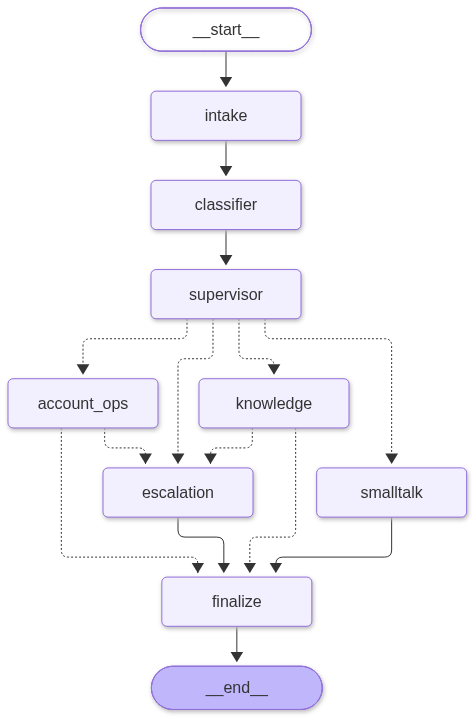

In [4]:
# IDEALLY YOUR ONLY IMPORT HERE IS:
# from agentic.workflow import orchestrator

from langchain_core.messages import HumanMessage
from agentic.workflow import orchestrator
from agentic.logging_utils import search_logs
from agentic.tools.memory_store import recall

from IPython.display import Image
Image(orchestrator.get_graph().draw_mermaid_png())

In [5]:
def ask(text, user, thread):
    cfg = {"configurable": {"thread_id": thread}}
    out = orchestrator.invoke({"messages": [HumanMessage(content=text)],
        "external_user_id": user, "channel": "chat", "account_id": "cultpass"}, cfg)
    print(out["route"], out["resolution"], out["confidence"], out["escalation_reason"])
    print(out["messages"][-1].content)
    return out

In [5]:
chat_interface(orchestrator, "1")

In [6]:
ask("Hi, I'm Bob and I love museums.", "f556c0", "mem-1")
ask("What did I say I love?", "f556c0", "mem-1")
list(orchestrator.get_state_history({"configurable": {"thread_id": "mem-1"}}))[0].values["messages"]

knowledge escalated 0.205411682984097 no_relevant_knowledge
I wasn't able to fully resolve this myself, so I've escalated your ticket to our human support team. They'll follow up with you soon.
knowledge escalated 0.12163246210821993 no_relevant_knowledge
I wasn't able to fully resolve this myself, so I've escalated your ticket to our human support team. They'll follow up with you soon.


[HumanMessage(content="Hi, I'm Bob and I love museums.", additional_kwargs={}, response_metadata={}, id='7fed2ecb-09fc-4d7a-b3fd-62509fbee8be'),
 AIMessage(content="I wasn't able to fully resolve this myself, so I've escalated your ticket to our human support team. They'll follow up with you soon.", additional_kwargs={}, response_metadata={}, id='c8d63488-e458-437a-8ce5-b2787a281fba'),
 HumanMessage(content='What did I say I love?', additional_kwargs={}, response_metadata={}, id='28cee853-f77f-4f1e-8d34-4b110bce8988'),
 AIMessage(content="I wasn't able to fully resolve this myself, so I've escalated your ticket to our human support team. They'll follow up with you soon.", additional_kwargs={}, response_metadata={}, id='fba6b495-ef56-49d2-a9af-952844c7c3b2')]

In [7]:
ask("I prefer email contact. How do I cancel my subscription?", "f556c0", "mem-2")
ask("Hello again, any tips for me?", "f556c0", "mem-3")   # new ticket, memory recalled
recall("f556c0", "contact preference")

knowledge escalated 0.301 low_confidence_kb_answer
I wasn't able to fully resolve this myself, so I've escalated your ticket to our human support team. They'll follow up with you soon.
knowledge escalated 0.2549774516479377 no_relevant_knowledge
I wasn't able to fully resolve this myself, so I've escalated your ticket to our human support team. They'll follow up with you soon.


[{'kind': 'preference',
  'text': 'email contact',
  'ticket_id': 'mem-2',
  'created_at': '2026-11-07T15:21:13.359383+00:00',
  'score': 0.5280070962310031},
 {'kind': 'preference',
  'text': 'contacted by email',
  'ticket_id': 'test-e3ce68f1',
  'created_at': '2026-11-07T15:11:45.631902+00:00',
  'score': 0.4970506168430632},
 {'kind': 'preference',
  'text': 'contacted by email',
  'ticket_id': 'test-f5d79320',
  'created_at': '2026-11-07T15:02:56.118323+00:00',
  'score': 0.496942597683222}]

In [9]:
import sqlite3
con = sqlite3.connect("data/core/udahub.db")
print(con.execute("select name from sqlite_master where type='table'").fetchall())

[('accounts',), ('users',), ('knowledge',), ('tickets',), ('ticket_metadata',), ('ticket_messages',)]


In [13]:
print(con.execute("select ticket_id, status, main_issue_type from ticket_metadata").fetchall())

[('394cd5f8-87c2-4065-9f50-6ebcf1c34d12', 'open', None), ('demo-428b61', 'resolved', 'smalltalk'), ('demo-cbc406', 'resolved', 'general'), ('demo-31b734', 'resolved', 'reservation'), ('demo-460d68', 'escalated', 'reservation'), ('demo-85fa90', 'escalated', 'billing'), ('demo-24e262', 'resolved', 'smalltalk'), ('test-198b9781', 'resolved', 'general'), ('test-1425b145', 'resolved', 'reservation'), ('test-4ffef8d9', 'escalated', 'reservation'), ('test-f1e1b061', 'escalated', 'billing'), ('test-76b6ba3c', 'resolved', 'smalltalk'), ('test-6f8427b2', 'resolved', 'smalltalk'), ('test-f5d79320', 'resolved', 'subscription'), ('demo-0c0a33', 'resolved', 'smalltalk'), ('demo-7093c9', 'resolved', 'general'), ('demo-45d613', 'resolved', 'reservation'), ('demo-1f0677', 'escalated', 'reservation'), ('demo-783b45', 'escalated', 'billing'), ('demo-d93b20', 'escalated', 'other'), ('test-12ea3fe8', 'resolved', 'general'), ('test-cbb4048f', 'resolved', 'reservation'), ('test-3cb3ccfb', 'escalated', 'reser